In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split,KFold,cross_val_score

from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.metrics import make_scorer, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import ElasticNetCV, LassoCV, LinearRegression, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures

In [ ]:
data  = pd.read_csv("/content/BostonHousing.csv")
data.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       501 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  b        506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


In [ ]:
data.describe()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
count,506.000000,506.000000,506.000000,506.000000,506.000000,501.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284341,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.705587,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.884000,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208000,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.625000,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [ ]:
data.median()

,0
crim,0.25651
zn,0.00000
indus,9.69000
chas,0.00000
nox,0.53800
rm,6.20800
age,77.50000
dis,3.20745
rad,5.00000
tax,330.00000


In [ ]:
data.isnull().sum()

,0
crim,0
zn,0
indus,0
chas,0
nox,0
rm,5
age,0
dis,0
rad,0
tax,0


In [ ]:
data[data["rm"].isnull()]

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
10,0.22489,12.5,7.87,0,0.524,NaN,94.3,6.3467,5,311,15.2,392.52,20.45,15.0
35,0.06417,0.0,5.96,0,0.499,NaN,68.2,3.3603,5,279,19.2,396.90,9.68,18.9
63,0.12650,25.0,5.13,0,0.453,NaN,43.4,7.9809,8,284,19.7,395.58,9.50,25.0
96,0.11504,0.0,2.89,0,0.445,NaN,69.6,3.4952,2,276,18.0,391.83,11.34,21.4
135,0.55778,0.0,21.89,0,0.624,NaN,98.2,2.1107,4,437,21.2,394.67,16.96,18.1


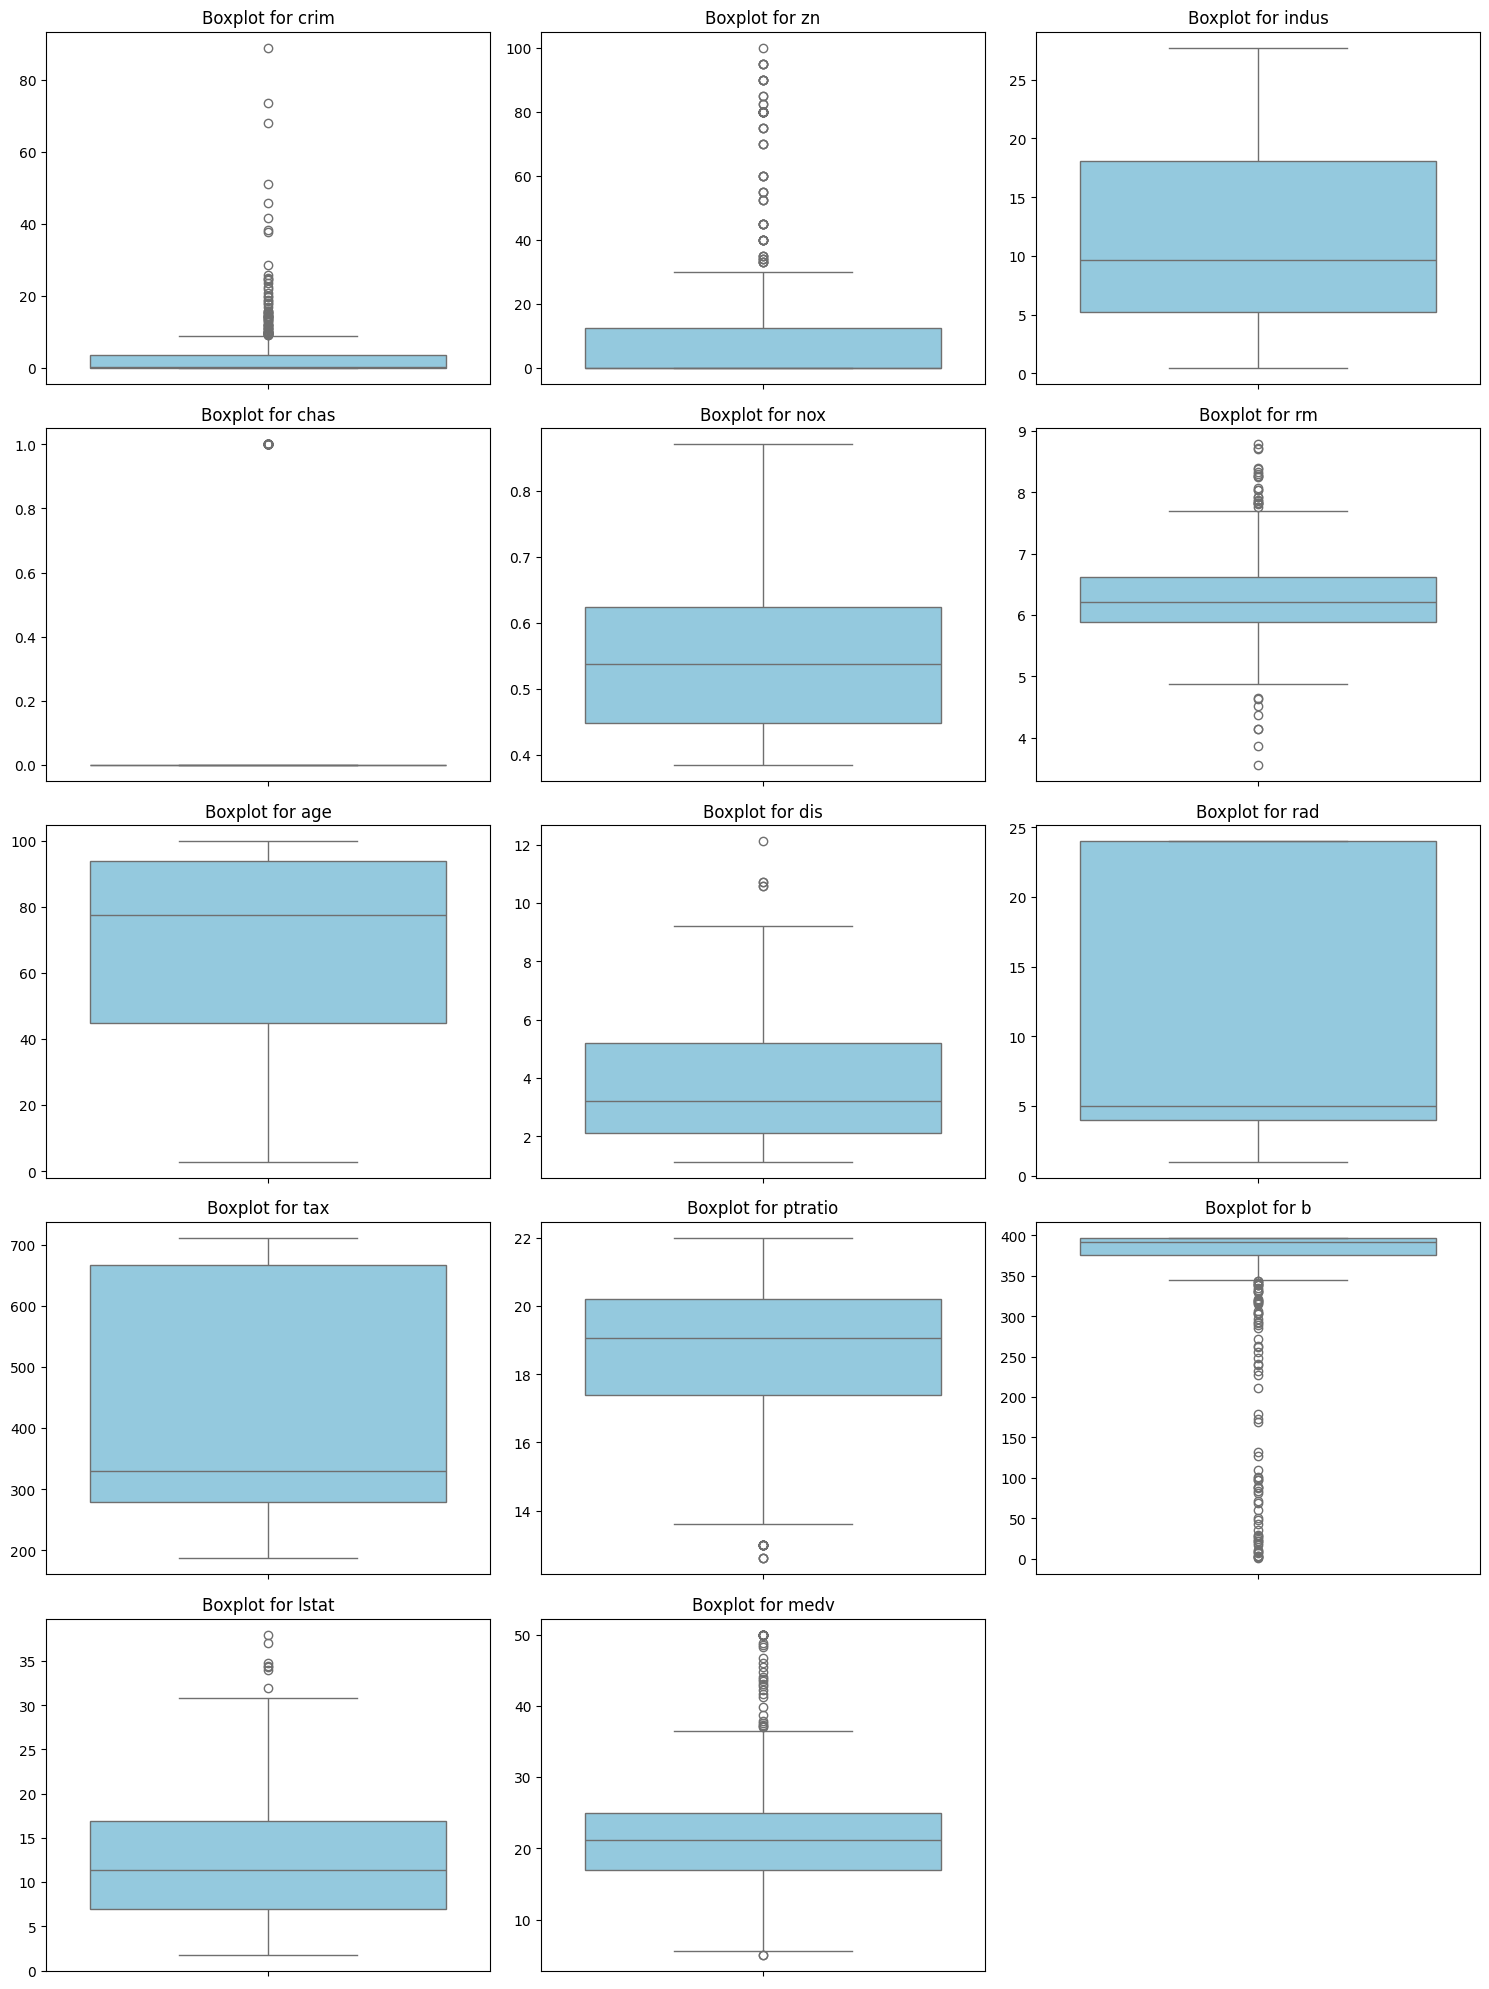

In [ ]:
num_cols = len(data.columns)
n_rows = (num_cols + 2) // 3

fig, axes = plt.subplots(nrows=n_rows, ncols=3, figsize=(15, n_rows * 4))
axes = axes.flatten()

for i, column in enumerate(data.columns):
    sns.boxplot(data=data, y=column, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Boxplot for {column}')
    axes[i].set_ylabel('')


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

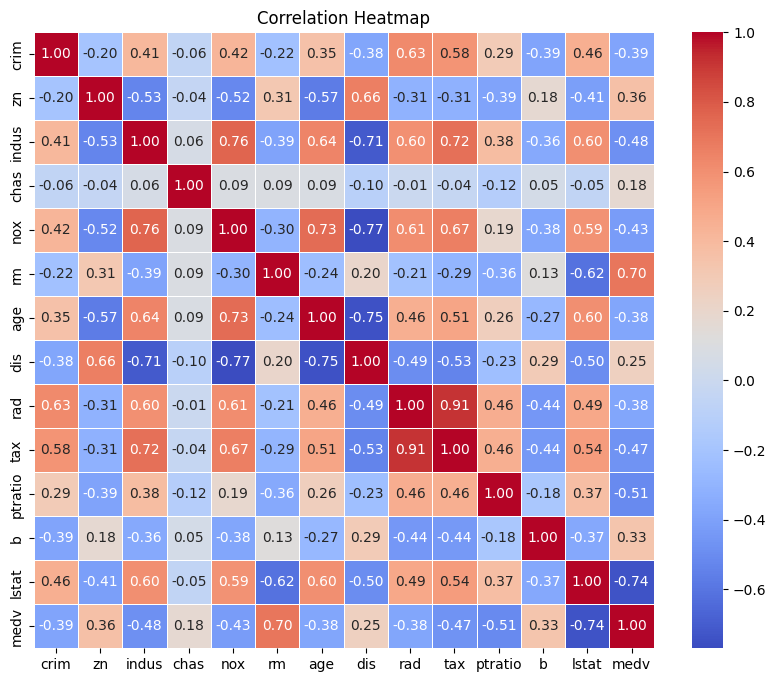

In [ ]:
matrix = data.corr()
plt.figure(figsize=(10,8))
sns.heatmap(matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

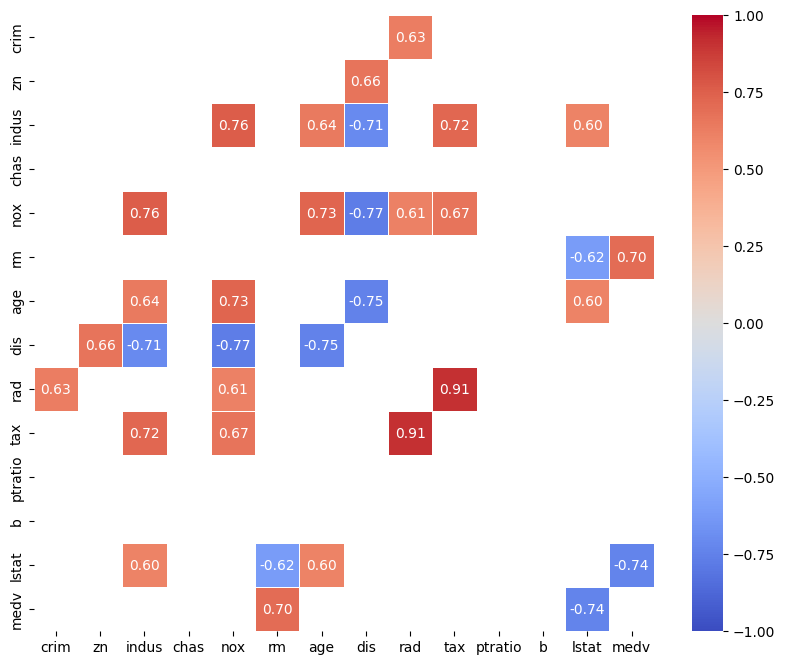

In [ ]:
matrix = data.corr()

mask = (matrix.abs() < 0.6) | (matrix.abs() == 1)

plt.figure(figsize=(10, 8))
sns.heatmap(matrix, annot=True, cmap="coolwarm", fmt=".2f",
            linewidths=0.5, mask=mask, vmin=-1, vmax=1, center=0)
plt.show()

In [ ]:
# columns_to_clip = ['crim', 'zn', 'rm', 'dis', 'ptratio', 'b', 'lstat']

# for col in columns_to_clip:
#     lower_limit = data[col].quantile(0.01)
#     upper_limit = data[col].quantile(0.99)
#     data[col] = np.clip(data[col], lower_limit, upper_limit)

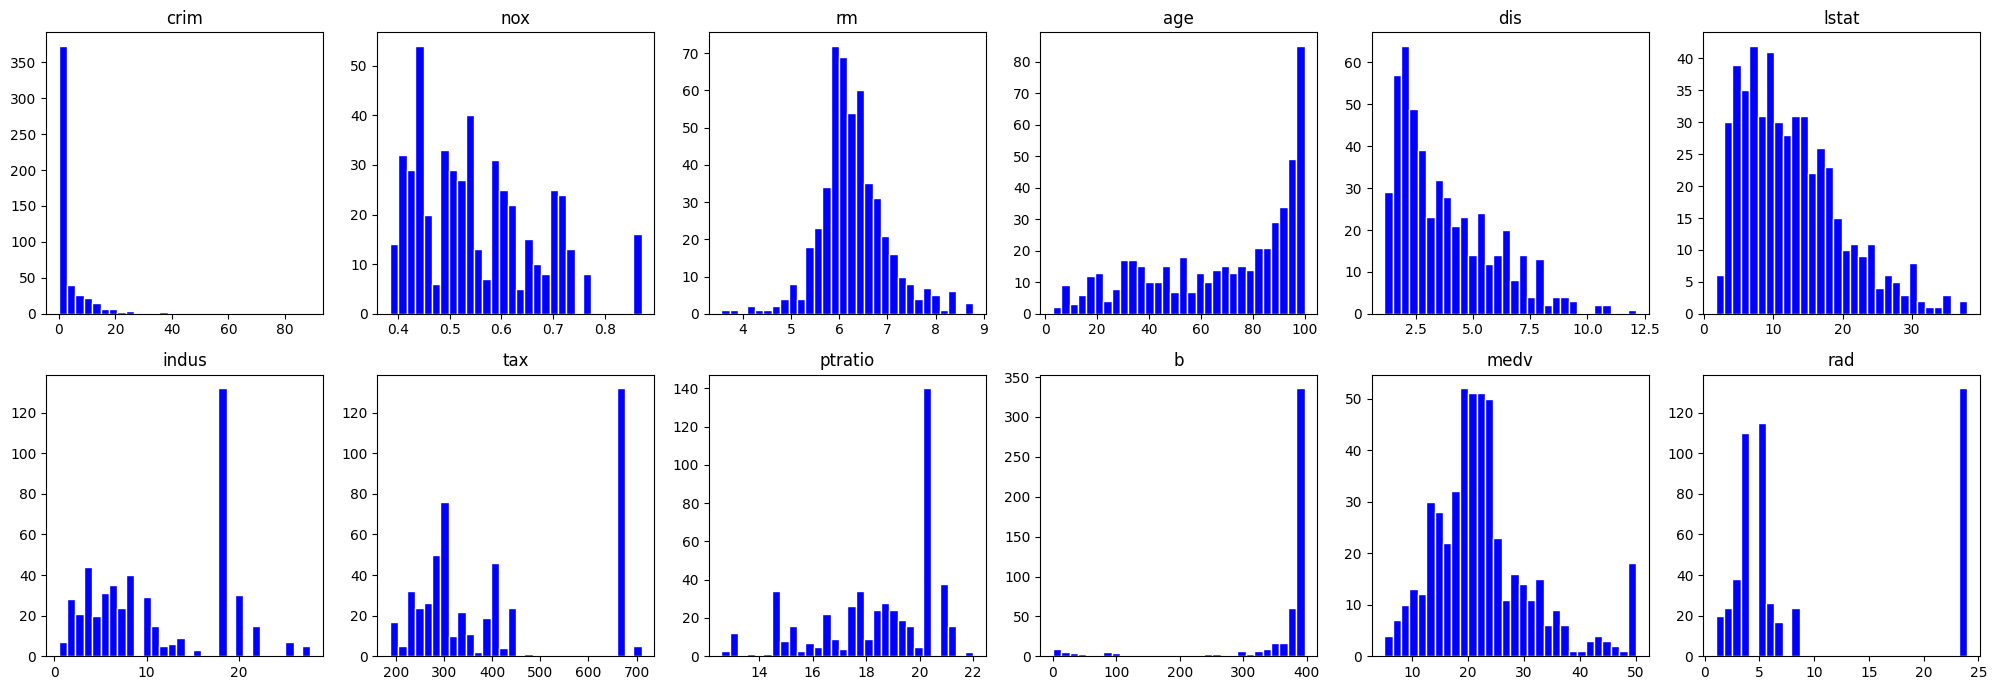

In [ ]:
cont_cols = ['crim', 'nox', 'rm', 'age', 'dis', 'lstat', 'indus', 'tax', 'ptratio', 'b',"medv","rad"]

fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for ax, col in zip(axes.ravel(), cont_cols):
    ax.hist(data[col], bins=30, color='blue', edgecolor='white')
    ax.set_title(col)
plt.tight_layout()
plt.show()

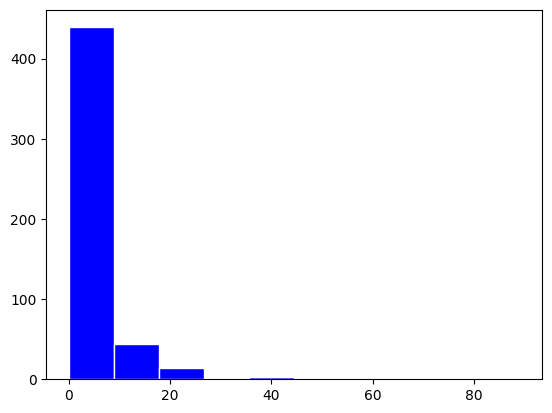

In [ ]:
plt.hist(data["crim"], color='blue', edgecolor='white')
plt.show()

In [ ]:
data[data['crim'] < 1]["crim"]

,crim
0,0.00632
1,0.02731
2,0.02729
3,0.03237
4,0.06905
...,...
501,0.06263
502,0.04527
503,0.06076
504,0.10959


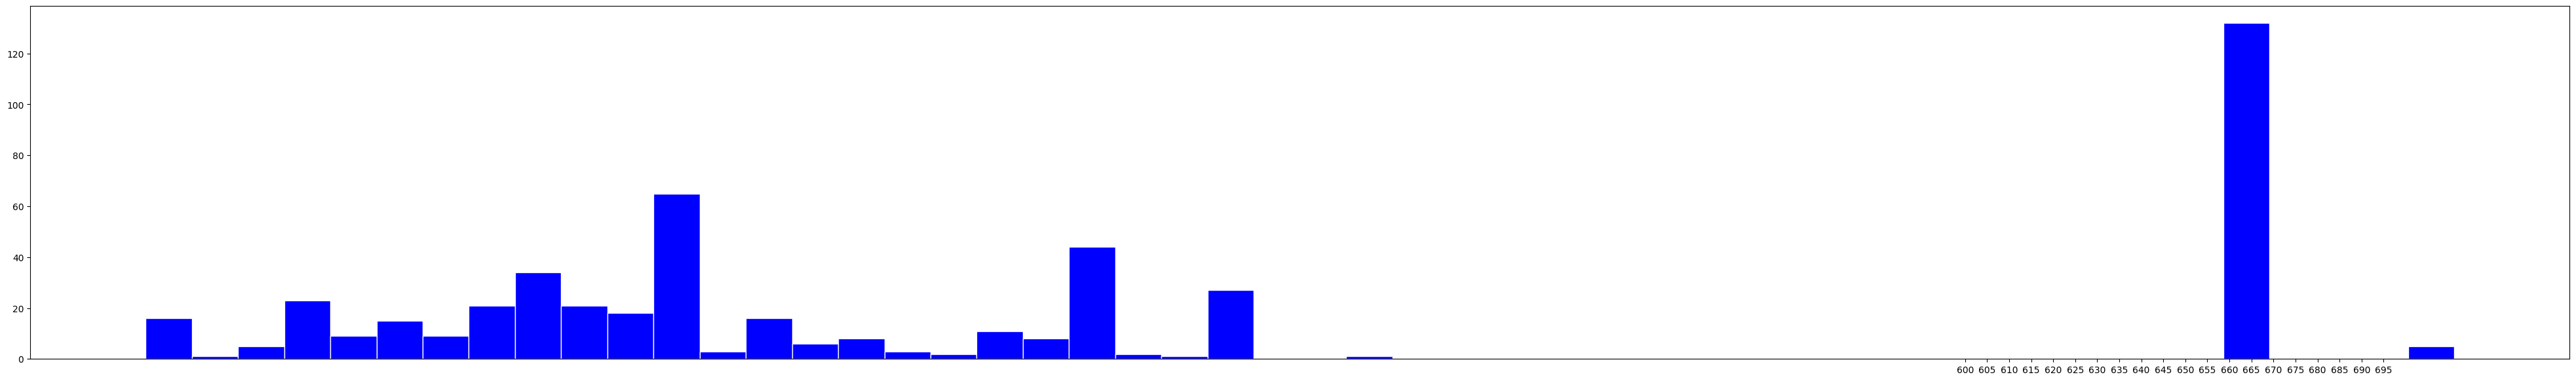

In [ ]:
plt.figure(figsize=(50, 7))

plt.hist(data["tax"], color='blue', edgecolor='white', bins=50)
plt.xticks(np.arange(600,700, 5))

plt.show()

In [ ]:
data[(data["tax"]>655) & (data["tax"]<670)]["tax"].value_counts()

,count
tax,
666,132


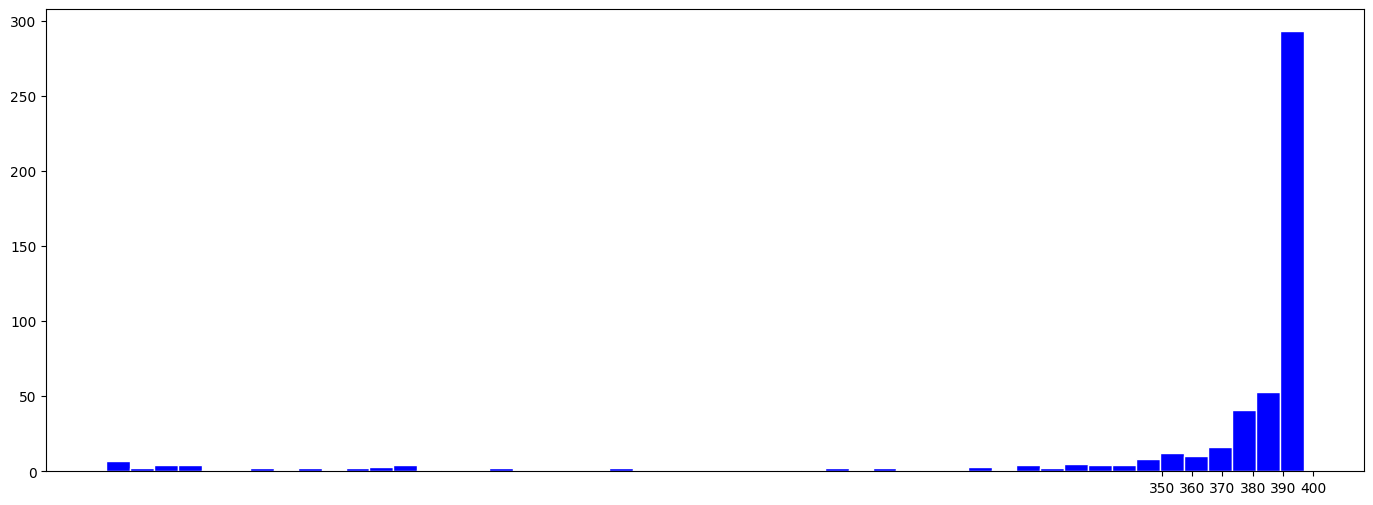

In [ ]:
plt.figure(figsize=(17, 6))

plt.hist(data["b"], color='blue', edgecolor='white', bins=50)
plt.xticks(np.arange(350, 401, 10))

plt.show()

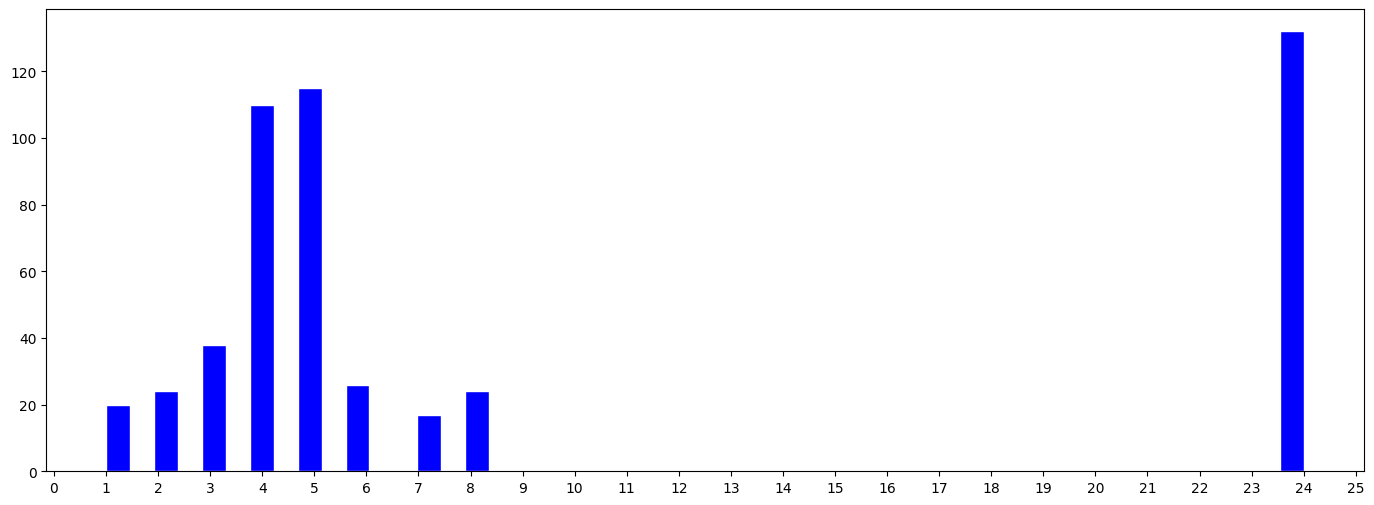

In [ ]:
plt.figure(figsize=(17, 6))

plt.hist(data["rad"], color='blue', edgecolor='white', bins=50)
plt.xticks(np.arange(0,26,1))

plt.show()

In [ ]:
data[data["rad"]>23]["rad"]

,rad
356,24
357,24
358,24
359,24
360,24
...,...
483,24
484,24
485,24
486,24


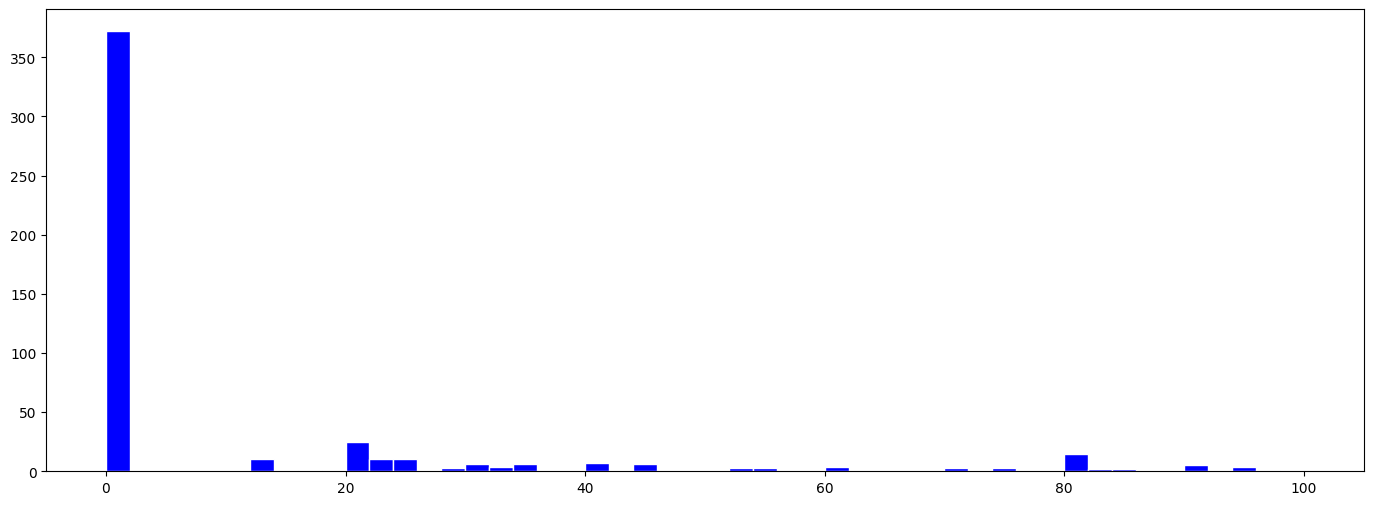

In [ ]:
plt.figure(figsize=(17, 6))

plt.hist(data["zn"], color='blue', edgecolor='white', bins=50)

plt.show()

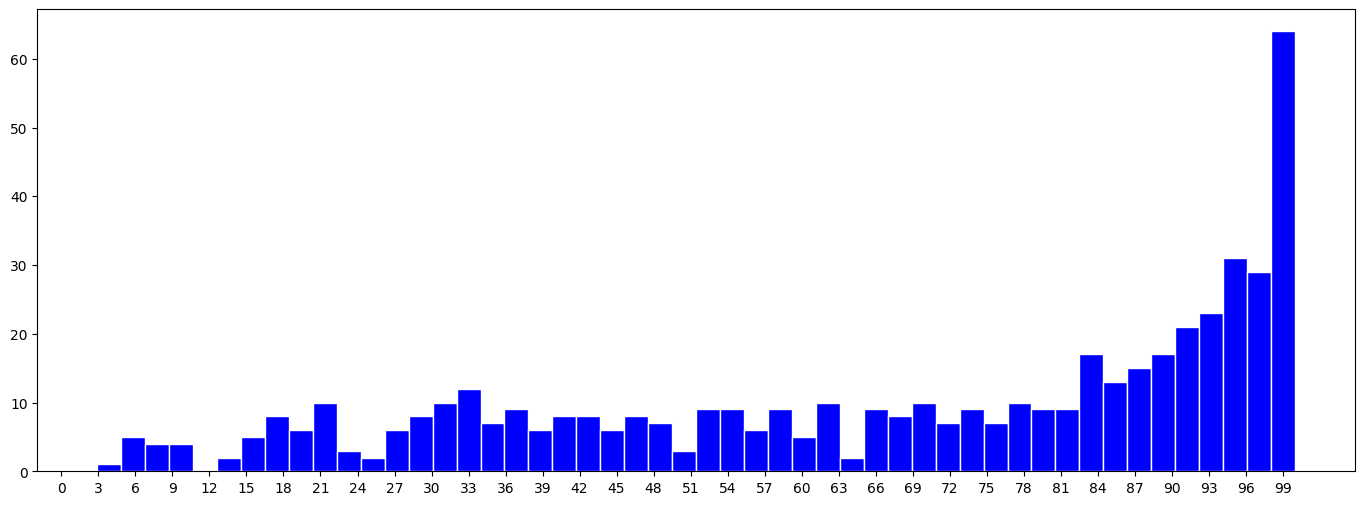

In [ ]:
plt.figure(figsize=(17, 6))

plt.hist(data["age"], color='blue', edgecolor='white', bins=50)
plt.xticks(np.arange(0, 100, 3))

plt.show()

In [ ]:
data[(data["age"]>84) & (data["age"] !=100)]["age"]

,age
7,96.1
9,85.9
10,94.3
14,84.5
20,98.1
...,...
489,98.3
490,98.0
491,98.8
503,91.0


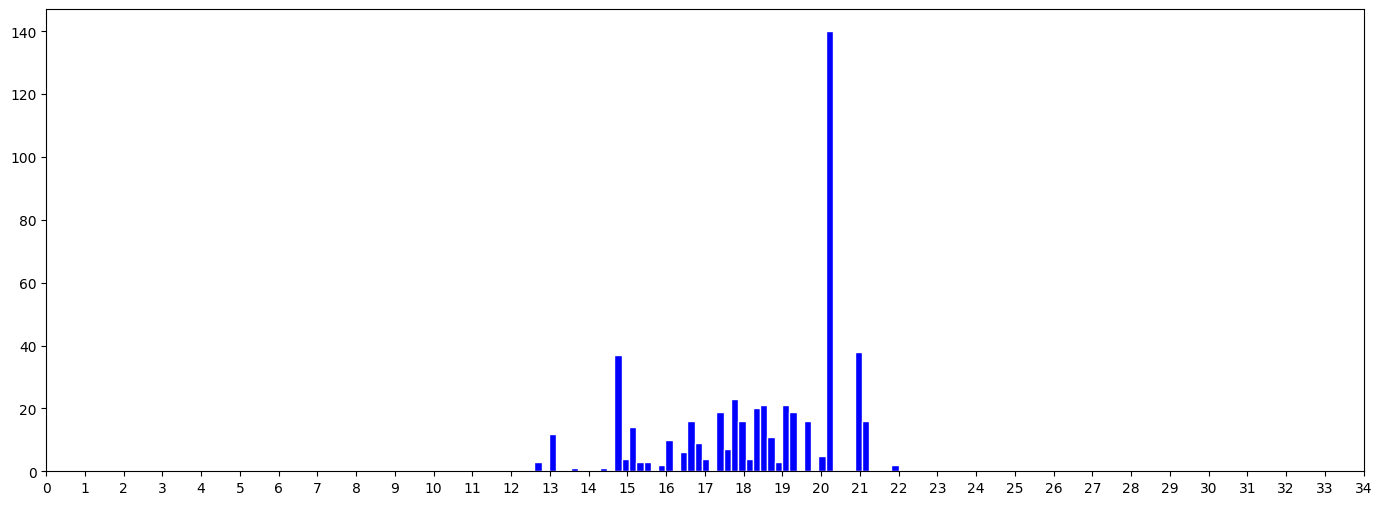

In [ ]:
plt.figure(figsize=(17, 6))

plt.hist(data["ptratio"], color='blue', edgecolor='white', bins=50)
plt.xticks(np.arange(0, 35, 1))
plt.show()

In [ ]:
data[(data["ptratio"]==20.2)]["ptratio"]

,ptratio
333,20.2
334,20.2
335,20.2
336,20.2
337,20.2
...,...
483,20.2
484,20.2
485,20.2
486,20.2


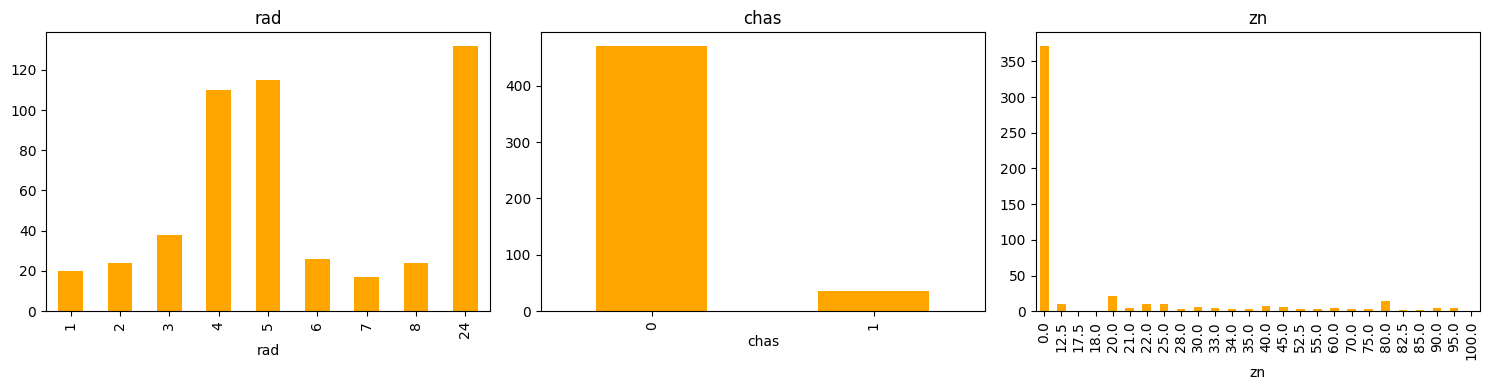

In [ ]:
disc_cols = ['rad', 'chas', 'zn']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, disc_cols):
    data[col].value_counts().sort_index().plot(kind='bar', ax=ax, color='orange')
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
data["zn"].value_counts()

,count
zn,
0.0,372
20.0,21
80.0,15
22.0,10
25.0,10
12.5,10
40.0,7
30.0,6
45.0,6


In [ ]:
data.columns

Index(['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax',
       'ptratio', 'b', 'lstat', 'medv'],
      dtype='object')

In [ ]:
df_missing = data.copy()

In [ ]:
imputer = IterativeImputer(
    max_iter=10,
    random_state=42,
    sample_posterior=False,
)

imputed_array = imputer.fit_transform(df_missing)
df_imputed = pd.DataFrame(imputed_array, columns=df_missing.columns)

In [ ]:
imputer = IterativeImputer(
    max_iter=10,
    random_state=42,
    sample_posterior=False,
)


imputed_array = imputer.fit_transform(df_missing.drop(columns=['medv']))


df_imputed = pd.DataFrame(
    imputed_array,
    columns=df_missing.drop(columns=['medv']).columns
)


df_imputed['medv'] = df_missing['medv'].values

In [ ]:
df_imputed.isnull().sum()

,0
crim,0
zn,0
indus,0
chas,0
nox,0
rm,0
age,0
dis,0
rad,0
tax,0


In [ ]:
X = df_imputed.drop(columns={"medv"})
y = df_imputed["medv"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
y_train = np.log1p(y_train)

In [ ]:
def transform_features(data: pd.DataFrame) -> pd.DataFrame:
    df_feat = data.copy()

    lstat_median = df_feat["lstat"].median()

    df_feat['tax_per_rm'] = df_feat['tax'] / df_feat['rm']
    df_feat['tax_per_rad'] = df_feat['tax'] / df_feat['rad']
    df_feat['is_max_rad'] = (df_feat['rad'] == 24).astype(int)
    df_feat['rm_x_lstat'] = df_feat['rm'] * df_feat['lstat']
    df_feat['nox_x_indus'] = df_feat['nox'] * df_feat['indus']
    df_feat['log_lstat'] = np.log1p(df_feat['lstat'])
    df_feat['log_crim'] = np.log1p(df_feat['crim'])
    df_feat['log_dis'] = np.log1p(df_feat['dis'])

    df_feat['tax_crim_logratio'] = np.log(df_feat['tax']) - np.log1p(df_feat['crim'])

    df_feat['nox_per_dis'] = df_feat['nox'] / df_feat['dis']
    df_feat['dis_per_nox'] = df_feat['dis'] / df_feat['nox']

    df_feat['nox_per_age'] = df_feat['nox'] / df_feat['age']
    df_feat['nox_age_exposure'] = df_feat['nox'] * df_feat['age'] / 100

    df_feat['nox_indus_geo'] = np.sqrt(df_feat['nox'] * df_feat['indus'])

    df_feat['indus_per_rad'] = df_feat['indus'] / df_feat['rad']
    df_feat['indus_per_rm'] = df_feat['indus'] / df_feat['rm']

    df_feat['tax_per_nox'] = df_feat['tax'] / df_feat['nox']
    df_feat['tax_nox_loginter'] = np.log(df_feat['tax']) + np.log(df_feat['nox'])

    df_feat['indus_per_dis'] = df_feat['indus'] / df_feat['dis']
    df_feat['indus_dis_logratio'] = np.log1p(df_feat['indus']) - np.log(df_feat['dis'])

    df_feat['lstat_per_rm'] = df_feat['lstat'] / df_feat['rm']
    df_feat['rm_x_dis'] = df_feat['rm'] * df_feat['dis']
    df_feat['rm_x_nox'] = df_feat['rm'] * df_feat['nox']
    df_feat['ptratio_x_lstat'] = df_feat['ptratio'] * df_feat['lstat']
    df_feat['crim_per_dis'] = df_feat['crim'] / df_feat['dis']


    df_feat['crim_per_rad'] = df_feat['crim'] / df_feat['rad']
    df_feat['crim_rad_loginter'] = np.log1p(df_feat['crim']) * np.log1p(df_feat['rad'])

    df_feat['tax_per_indus'] = df_feat['tax'] / df_feat['indus']
    df_feat['indus_x_tax'] = df_feat['indus'] * df_feat['tax'] / 1000

    df_feat["lstat_high"] = (df_feat['lstat'] < lstat_median).astype(int)
    df_feat["lstat_low"] = (df_feat['lstat'] > lstat_median).astype(int)

    df_feat['age_per_dis'] = df_feat['age'] / df_feat['dis']
    df_feat['old_near_center'] = ((df_feat['age'] > 80) & (df_feat['dis'] < 3)).astype(int)
    df_feat["age_dis"] = df_feat["age"] * df_feat["dis"]
    df_feat['is_calm_crim'] = (df_feat['crim'] < 1).astype(int)
    df_feat['is_max_b'] = (df_feat['b'] > 370).astype(int)
    df_feat['is_high_tax'] = ((df_feat["tax"]>655) & (df_feat["tax"]<670)).astype(int)

    df_feat['has_zn'] = (df_feat['zn'] > 0).astype(int)
    df_feat['is_age_100'] = (df_feat['age'] >= 98).astype(int)
    df_feat['is_age_old'] = (df_feat['age'] > 84).astype(int)
    df_feat['is_ptr_202'] = np.isclose(df_feat['ptratio'], 20.2).astype(int)
    df_feat['is_ptr_high'] = (df_feat['ptratio'] >= 20.9).astype(int)

    return df_feat

In [ ]:
X_train = transform_features(X_train)

In [ ]:
def r2_in_original_scale(y_true_log, y_pred_log):
    y_true = np.expm1(y_true_log)
    y_pred = np.expm1(y_pred_log)
    return r2_score(y_true, y_pred)

real_r2_scorer = make_scorer(r2_in_original_scale)

In [ ]:
kf = KFold(n_splits=10, shuffle=True, random_state=42)

alphas = np.logspace(-4, 4, 80)

models = {
    "Ridge": make_pipeline(
        StandardScaler(),
        RidgeCV(alphas=alphas, cv=5, scoring="neg_mean_squared_error"),
    ),
    "Lasso": make_pipeline(
        StandardScaler(),
        LassoCV(
            alphas=alphas,
            cv=5,
            max_iter=10000,
            tol=1e-4,
            random_state=42,
        ),
    ),
    "ElasticNet": make_pipeline(
        StandardScaler(),
        ElasticNetCV(
            alphas=alphas,
            l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.99],
            cv=5,
            max_iter=10000,
            tol=1e-4,
            random_state=42,
        ),
    ),
    "Linear": LinearRegression(),
    "Polynomial": make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        RidgeCV(alphas=alphas, cv=5, scoring="neg_mean_squared_error"),
    ),
}

fitted_models = {}
cv_r2 = {}

for name, estimator in models.items():
    scores = cross_val_score(
        estimator, X_train, y_train, cv=kf, scoring=real_r2_scorer, n_jobs=-1
    )
    fitted_models[name] = estimator.fit(X_train, y_train)
    cv_r2[name] = scores.mean()
    print(f"{name}: средний CV R2 в исходной шкале = {scores.mean():.4f}")


model = fitted_models["Linear"]

Ridge: средний CV R2 в исходной шкале = 0.7943


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.00533566929503948, tolerance: 0.004606015184019518
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.05166480809298335, tolerance: 0.004606015184019518
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.00931722754019848, tolerance: 0.004606015184019518
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681:

Lasso: средний CV R2 в исходной шкале = 0.7899


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.006231065434713301, tolerance: 0.004606015184019518
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.009813498876361848, tolerance: 0.004606015184019518
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.0502809943498459, tolerance: 0.004606015184019518
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681

ElasticNet: средний CV R2 в исходной шкале = 0.7914
Linear: средний CV R2 в исходной шкале = 0.7950
Polynomial: средний CV R2 в исходной шкале = 0.8603


In [ ]:
polim = fitted_models["Polynomial"]

In [ ]:
X_test = transform_features(X_test)

               MAE      MSE    RMSE       R2
Model                                       
Ridge       2.1970  12.4878  3.5338  82.1672
Lasso       2.2057  12.4394  3.5270  82.2363
ElasticNet  2.2043  12.6611  3.5582  81.9198
Linear      2.1769  11.6794  3.4175  83.3217
Polynomial  2.0394  12.5343  3.5404  82.1008


/tmp/ipykernel_2314/483775516.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics_df.index, y=metrics_df[col], ax=axes[i], palette="viridis")
/tmp/ipykernel_2314/483775516.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics_df.index, y=metrics_df[col], ax=axes[i], palette="viridis")
/tmp/ipykernel_2314/483775516.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics_df.index, y=metrics_df[col], ax=axes[i], palette="viridis")
/tmp/ipykernel_2314/483775516.py:21: FutureWarning: 

Passing `palette` without assignin

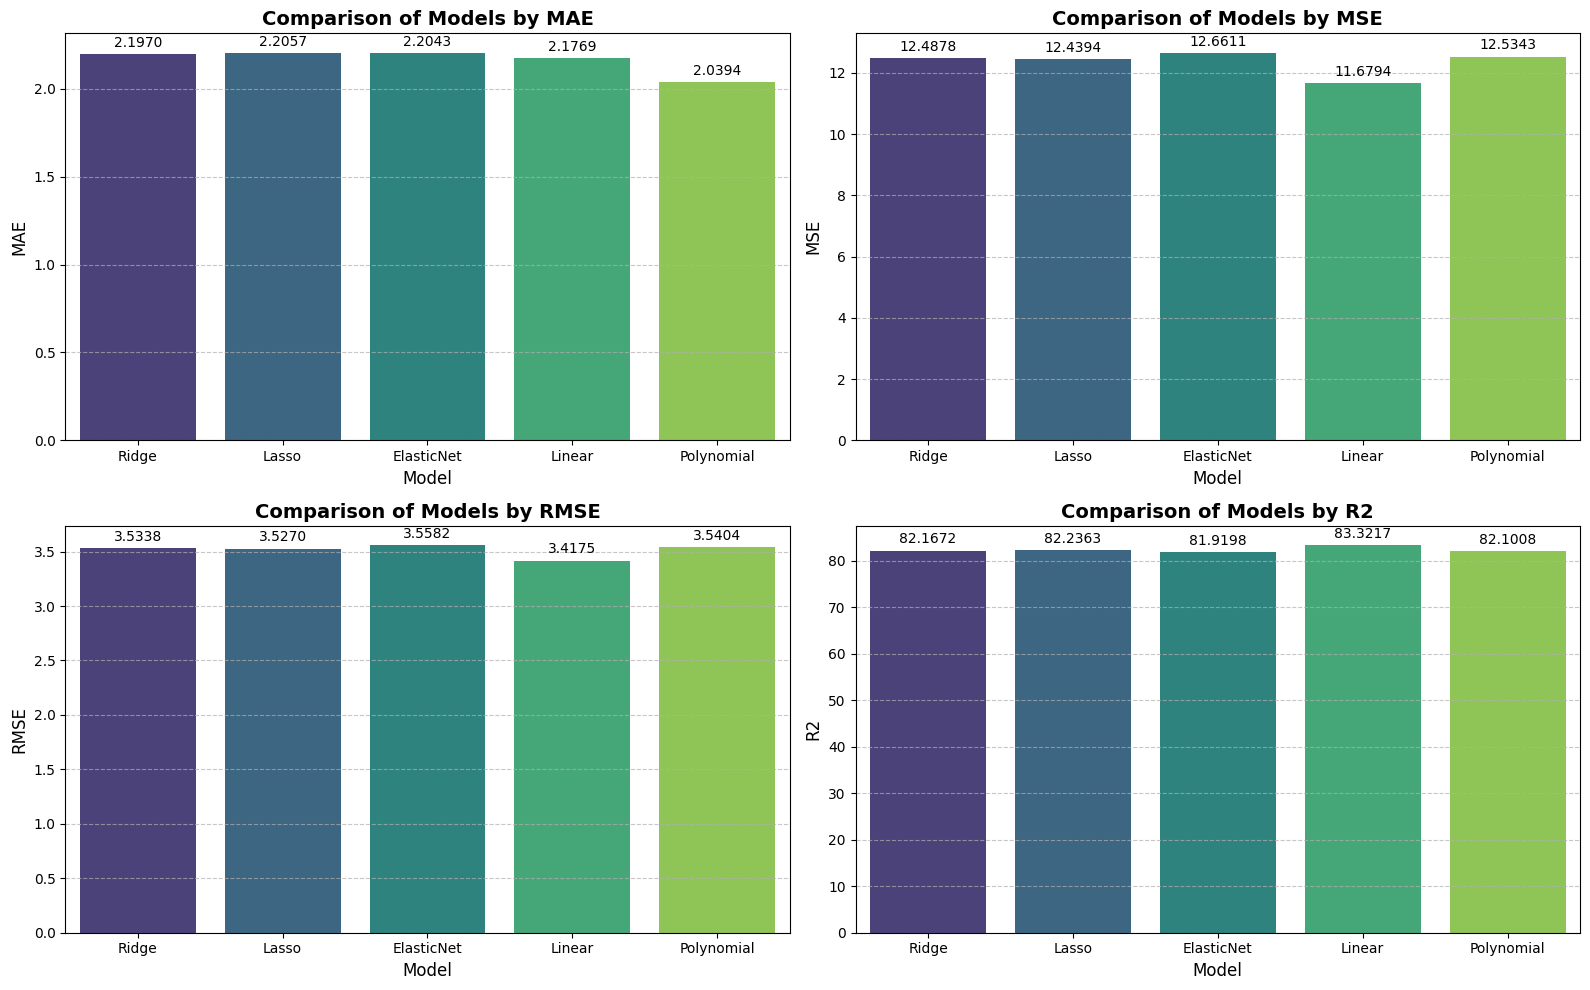

In [ ]:
results = []
for name, estimator in fitted_models.items():
    pred_log = estimator.predict(X_test)
    y_pred = np.expm1(pred_log)
    mse = mean_squared_error(y_test, y_pred)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test, y_pred)*100,
    })

metrics_df = pd.DataFrame(results).set_index("Model")
print(metrics_df.round(4).to_string())

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(metrics_df.columns):
    sns.barplot(x=metrics_df.index, y=metrics_df[col], ax=axes[i], palette="viridis")
    axes[i].set_title(f"Comparison of Models by {col}", fontsize=14, fontweight='bold')
    axes[i].set_xlabel("Model", fontsize=12)
    axes[i].set_ylabel(col, fontsize=12)
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

    for container in axes[i].containers:
        axes[i].bar_label(container, fmt='%.4f', padding=3)

plt.tight_layout()
plt.show()

In [ ]:
X_test.columns

Index(['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax',
       'ptratio', 'b', 'lstat', 'tax_per_rm', 'tax_per_rad', 'is_max_rad',
       'rm_x_lstat', 'nox_x_indus', 'log_lstat', 'log_crim', 'log_dis',
       'tax_crim_logratio', 'nox_per_dis', 'dis_per_nox', 'nox_per_age',
       'nox_age_exposure', 'nox_indus_geo', 'indus_per_rad', 'indus_per_rm',
       'tax_per_nox', 'tax_nox_loginter', 'indus_per_dis',
       'indus_dis_logratio', 'lstat_per_rm', 'rm_x_dis', 'rm_x_nox',
       'ptratio_x_lstat', 'crim_per_dis', 'crim_per_rad', 'crim_rad_loginter',
       'tax_per_indus', 'indus_x_tax', 'lstat_high', 'lstat_low',
       'age_per_dis', 'old_near_center', 'age_dis', 'is_calm_crim', 'is_max_b',
       'is_high_tax', 'has_zn', 'is_age_100', 'is_age_old', 'is_ptr_202',
       'is_ptr_high'],
      dtype='object')

In [ ]:
len(X_test.columns) -13

42

In [ ]:
crim     = 0.6
zn       = 18.0
indus    = 2.31
chas     = 0
nox      = 0.538
rm       = 6.575
age      = 65.2
dis      = 4.0900
rad      = 1
tax      = 296
ptratio  = 15.3
b        = 396.90
lstat    = 4.98

input_df = pd.DataFrame([{
    "crim": crim,
    "zn": zn,
    "indus": indus,
    "chas": chas,
    "nox": nox,
    "rm": rm,
    "age": age,
    "dis": dis,
    "rad": rad,
    "tax": tax,
    "ptratio": ptratio,
    "b": b,
    "lstat": lstat
}])


input_transformed = transform_features(input_df)


pred_log = model.predict(input_transformed)
prediction = np.expm1(pred_log)[0]

print(prediction)

22.101594245295296


In [ ]:
importance = pd.Series(
    model.coef_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance)

nox                   7.801487
log_crim              2.878791
tax_crim_logratio     1.760694
nox_indus_geo         0.400376
is_high_tax           0.288146
is_max_rad            0.288146
rm                    0.190244
rm_x_nox              0.090185
lstat                 0.073362
crim                  0.067836
is_calm_crim          0.065063
is_ptr_high           0.063233
age_per_dis           0.062421
chas                  0.061930
indus                 0.058078
lstat_low             0.041366
lstat_per_rm          0.022551
is_age_old            0.018541
tax_per_rm            0.016135
rm_x_dis              0.015799
ptratio               0.012503
rad                   0.010286
age_dis               0.003045
tax_per_nox           0.000766
zn                    0.000588
b                     0.000508
tax_per_indus         0.000199
tax_per_rad           0.000069
dis_per_nox          -0.000529
tax                  -0.002282
indus_per_dis        -0.003283
ptratio_x_lstat      -0.003609
rm_x_lst